In [1]:
from pennylane import numpy as np
import pennylane as qml
import itertools
from itertools import combinations
from scipy.optimize import minimize
from math import comb
import qaoa_aux 

In [2]:
def U_B(beta,edge_list):
    for edge_idx, (u, v) in enumerate(edge_list):
        theta = beta[edge_idx]
        qml.S(wires=u)
        qml.SingleExcitationMinus(-2 * theta,wires=[u, v])
        qml.adjoint(qml.S)(wires=u)

In [3]:
def U_C(gamma,cost_terms):
    # we have term index + cost terms so all the even numbered ZZ's
    for term_idx, (_, wires, coeff) in enumerate(cost_terms):
        theta = 2 * gamma[term_idx] * coeff
        # example for 4 consectuve z's
        #qml.PauliRot(theta, "ZZZZ", wires=[0,1,2,3])
        qml.PauliRot(theta,"Z" * len(wires),wires=list(wires))

In [4]:
def objective(gammas, betas, circuit,hyperedge_list, cost_terms, weights):
    expectation_values = circuit(gammas, betas)

    # Store weighted expected cut value for each hyperedge
    edge_values = []
    for edge_idx, edge in enumerate(hyperedge_list):
        k = len(edge)
        # Weighted constant term for this hyperedge
        edge_value = weights[edge_idx] * (1 - 1 / (2 ** (k - 1)))

        # Add the Pauli-Z terms belonging to this hyperedge
        for term_idx, (source_edge_idx, wires, coeff) in enumerate(cost_terms):

            if source_edge_idx == edge_idx:
                edge_value += coeff * expectation_values[term_idx]

        edge_values.append(edge_value)

    # Negative because Adam minimizes
    return -qml.math.min(qml.math.stack(edge_values))

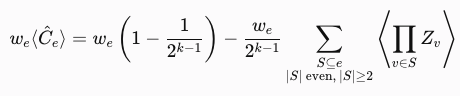

In [5]:

def run_qaoa(
    hyperedge_list,
    n,
    weights,
    num_layers=1,
    seed=42,
    scaling_constant=0.1,
    step_size=0.01,
    max_trials=100
):
    n_wires = n
    assert len(weights) == len(hyperedge_list)

    # Build mixer edges and cost terms
    edge_list = qaoa_aux.clique_expansion(hyperedge_list)
    cost_terms = qaoa_aux.build_cost_terms(hyperedge_list, weights)

    # Balanced initial state
    target_weight = (n_wires + 1) // 2
    initial_state = qaoa_aux.make_dicke_state(n_wires, target_weight)

    dev = qml.device("lightning.qubit", wires=n_wires)

    @qml.qnode(dev)
    def circuit(gammas, betas):
        qml.StatePrep(initial_state, wires=range(n_wires))

        for layer in range(num_layers):
            U_C(gammas[:, layer], cost_terms)
            U_B(betas[:, layer], edge_list)

        observables = []

        for _, wires, _ in cost_terms:
            z_term = qml.prod(*[qml.PauliZ(wire) for wire in wires])
            observables.append(qml.expval(z_term))

        return observables

    # Random parameter initialization
    rng = np.random.default_rng(seed)

    beta_params = np.array(
        scaling_constant * rng.random((len(edge_list), num_layers)),
        requires_grad=True
    )

    gamma_params = np.array(
        scaling_constant * rng.random((len(cost_terms), num_layers)),
        requires_grad=True
    )

    opt = qml.AdamOptimizer(stepsize=step_size)
    objective_values = []

    # Fair-cut objective returns NEGATIVE minimum coverage
    initial_loss = objective(gamma_params, beta_params, circuit,hyperedge_list, cost_terms, weights)

    objective_values.append(-float(initial_loss))

    print(f"Initial fair cut = {-float(initial_loss):.6f}")

    # Optimization
    for trial in range(max_trials):

        gamma_params, beta_params = opt.step(
            lambda g, b: objective(
                g,
                b,
                circuit,
                hyperedge_list,
                cost_terms,
                weights
            ),
            gamma_params,
            beta_params
        )

        current_loss = objective(gamma_params, beta_params, circuit,hyperedge_list, cost_terms, weights)

        fair_cut_value = -float(current_loss)
        objective_values.append(fair_cut_value)

        if trial % 10 == 0:
            print(
                f"Iteration {trial:3d} | "
                f"fair cut = {fair_cut_value:.6f}"
            )

    return {
        "gammas": gamma_params,
        "betas": beta_params,
        "objective_values": objective_values,
        "circuit": circuit,
        "edge_list": edge_list,
        "cost_terms": cost_terms,
        "n_wires": n_wires
    }


In [6]:
P = np.load("../data/poisson_16_12_3/P/03.npy")
w= np.load("../data/poisson_16_12_3/w/03.npy")

hyperedge_list = qaoa_aux.matrix_to_hyperedges(P)

In [8]:

result = run_qaoa(
    hyperedge_list,
    weights=w,
    n=12,
    num_layers=3,
    seed=42,
    scaling_constant=0.1,
    step_size=0.05,
    max_trials=300
)

Initial fair cut = 0.405868
Iteration   0 | fair cut = 0.474440
Iteration  10 | fair cut = 0.787979
Iteration  20 | fair cut = 0.806305
Iteration  30 | fair cut = 0.841056
Iteration  40 | fair cut = 0.877515
Iteration  50 | fair cut = 0.907516
Iteration  60 | fair cut = 0.924639
Iteration  70 | fair cut = 0.939052
Iteration  80 | fair cut = 0.945622
Iteration  90 | fair cut = 0.944892
Iteration 100 | fair cut = 0.948837
Iteration 110 | fair cut = 0.951137
Iteration 120 | fair cut = 0.950481
Iteration 130 | fair cut = 0.961474
Iteration 140 | fair cut = 0.957164
Iteration 150 | fair cut = 0.962412
Iteration 160 | fair cut = 0.964800
Iteration 170 | fair cut = 0.968247
Iteration 180 | fair cut = 0.974987
Iteration 190 | fair cut = 0.969489
Iteration 200 | fair cut = 0.972270
Iteration 210 | fair cut = 0.975560
Iteration 220 | fair cut = 0.973321
Iteration 230 | fair cut = 0.967013
Iteration 240 | fair cut = 0.973077
Iteration 250 | fair cut = 0.972800
Iteration 260 | fair cut = 0.974019
